In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.family'] = 'Apple SD Gothic Neo'

### 검증용/학습용 데이터 분리

In [4]:
df = pd.read_csv("../data/1차 전처리(센서 제거)/train1_sens_filter.csv", index_col=0)

rng = np.random.default_rng(42)                 # 시드 고정 → 누가 돌려도 같은 분할
engines = np.sort(df["engine_id"].unique())
replay_ids = np.sort(rng.choice(engines, size=20, replace=False))

split = pd.DataFrame({"engine_id": engines})
split["role"] = np.where(split["engine_id"].isin(replay_ids), "replay", "dev")

# 개발용 80대에 폴드 번호 부여 (엔진 단위)
dev_ids = split.loc[split.role == "dev", "engine_id"].to_numpy()
fold_of = {e: i % 5 for i, e in enumerate(rng.permutation(dev_ids))}
split["fold"] = split["engine_id"].map(fold_of)   # replay는 NaN

Path("../data/split").mkdir(exist_ok=True)
split.to_csv("../data/split/engine_split.csv", index=False)

# 확인: 두 그룹의 수명 분포가 크게 다르지 않은지
life = df.groupby("engine_id")["cycle"].max()
print(split.role.value_counts())
print(life.groupby(split.set_index("engine_id")["role"]).describe().round(1))

role
dev       80
replay    20
Name: count, dtype: int64
        count   mean   std    min    25%    50%    75%    max
role                                                         
dev      80.0  204.9  44.5  128.0  177.8  199.0  223.8  341.0
replay   20.0  212.0  53.9  150.0  176.0  196.5  237.2  362.0


### 라벨 및 평가 함수

In [5]:
def cap_rul(rul, cap):
    """구간 선형 라벨: 상한 이상은 cap으로 자름 (학습 라벨 전용)"""
    return np.minimum(rul, cap)

def phm_score(y_true, y_pred):
    """PHM08 비대칭 점수. d>0(늦은 예측)이 더 큰 벌점. 낮을수록 좋음"""
    d = np.asarray(y_pred) - np.asarray(y_true)
    return np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))

def evaluate(y_true_raw, y_pred, eval_max=115):
    """채점은 상한을 씌우지 않은 실제 RUL로, 세 상한 후보가 공통으로 다루는 RUL<=115 구간만"""
    y_true_raw, y_pred = np.asarray(y_true_raw), np.asarray(y_pred)
    m = y_true_raw <= eval_max
    yt, yp = y_true_raw[m], y_pred[m]
    return {"rmse": np.sqrt(np.mean((yp - yt) ** 2)),
            "phm_mean": phm_score(yt, yp) / len(yt),   # 행 수가 폴드마다 달라 평균으로
            "late_ratio": np.mean(yp > yt)}            # 늦게 예측한 비율

### 평균 예측 베이스라인(최소 기준)

In [7]:
dev = df.merge(split, on="engine_id").query("role == 'dev'")

rows = []
for cap in [115, 130, 150]:
    for k in range(5):
        tr, va = dev[dev.fold != k], dev[dev.fold == k]
        pred = np.full(len(va), cap_rul(tr["RUL"], cap).mean())   # 학습 폴드 라벨 평균
        rows.append({"cap": cap, "fold": k, **evaluate(va["RUL"], pred)})
base = pd.DataFrame(rows)
base.groupby("cap")[["rmse", "phm_mean", "late_ratio"]].agg(["mean", "std"]).round(2)

rmse       phm_mean        late_ratio      
      mean   std     mean    std       mean   std
cap                                              
115  41.75  0.26   345.12  14.76       0.71  0.00
130  45.59  0.38   628.01  34.20       0.77  0.00
150  50.09  0.54  1182.12  84.00       0.82  0.01

>  최소 평가 기준 만듬   
> - 학습용 엔진들의 RUL 상한(무릎값평균 : 115)을 적용한 뒤, 그 값을 평균냄 = 각 행의 평균 RUL은 82사이클
> - 검증용 엔진들의 상한은 그대로 82로 결정   
> - 그때 검증용 엔진의 RMSE값은 41.75 = 41사이클.  
이때 RMSE값의 의미 : 41사이클의 크기만큼 오차가 있음. 
예를 들어 5-4-3-2-1의 실제 RUL값을 7-6-5-4-3 으로 예측했다면 오차는 2-2-2-2-2, 20/5 = 2이고, 다시 제곱근을 씌워서 2가됨.   
RMSE는 큰 오차에 큰 벌점을 주는 방법이기 때문에, 오차가 큰 경우에는 더 커지게됨. 예를들어 5-4-

In [8]:
SENSORS = ["s2","s3","s4","s7","s8","s11","s12","s13","s15","s17","s20","s21"]

def make_features(hist, N=20, sensors=SENSORS):
    """
    hist: engine_id, cycle, 센서 열을 가진 DataFrame (한 엔진 또는 여러 엔진)
    반환: 각 행마다 '그 시점까지의 최근 N사이클'로만 계산한 특징 (과거만 사용)
      - {s}_mean: 최근 N사이클 평균
      - {s}_slope: 최근 N사이클 기울기 (사이클당 변화량)
    """
    hist = hist.sort_values(["engine_id", "cycle"])
    g = hist.groupby("engine_id", sort=False)
    t = hist["cycle"].astype(float)

    def rmean(s):  # 엔진별 rolling 평균, 초반엔 있는 만큼만
        return s.groupby(hist["engine_id"], sort=False) \
                .transform(lambda x: x.rolling(N, min_periods=1).mean())

    mt, mtt = rmean(t), rmean(t * t)
    var_t = mtt - mt ** 2                       # 윈도우 안 사이클의 분산

    out = hist[["engine_id", "cycle"]].copy()
    for s in sensors:
        x = hist[s].astype(float)
        mx, mtx = rmean(x), rmean(t * x)
        out[f"{s}_mean"] = mx
        # 최소제곱 기울기 = cov(t,x)/var(t). 첫 사이클은 var=0이라 0으로 처리
        out[f"{s}_slope"] = np.where(var_t > 1e-9, (mtx - mt * mx) / var_t.where(var_t > 1e-9, 1), 0.0)
    return out

In [9]:
N = 20
batch = make_features(df, N=N)

# 실시간 흉내: 엔진 1번의 각 사이클마다 '최근 N줄 버퍼'만 넣고 마지막 줄을 꺼냄
e1 = df[df.engine_id == 1].sort_values("cycle")
stream = pd.concat([make_features(e1.iloc[max(0, i - N + 1): i + 1], N=N).tail(1)
                    for i in range(len(e1))])

feat_cols = [c for c in batch.columns if c.endswith(("_mean", "_slope"))]
b1 = batch[batch.engine_id == 1][feat_cols].to_numpy()
print("최대 차이:", np.abs(b1 - stream[feat_cols].to_numpy()).max())
print("일치:", np.allclose(b1, stream[feat_cols].to_numpy()))

최대 차이: 3.5012127745648325e-12
일치: True


### 선형회귀 베이스라인

센서별 열화 곡선은 지수함수를 나타내기 때문에 비선형성을 가짐. 따라서 선형 회귀는 적합한 선이 아님.    
베이스라인을 정하는 것이기 때문에 간단한 선형회귀로 일단 표현.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

feats = make_features(df, N=20).merge(df[["engine_id", "cycle", "RUL"]], on=["engine_id", "cycle"])
feats = feats.merge(split, on="engine_id").query("role == 'dev'")
X_cols = [c for c in feats.columns if c.endswith(("_mean", "_slope"))]

rows = []
for cap in [115, 130, 150]:
    for k in range(5):
        tr, va = feats[feats.fold != k], feats[feats.fold == k]
        model = make_pipeline(StandardScaler(), LinearRegression())
        model.fit(tr[X_cols], cap_rul(tr["RUL"], cap))      # 학습 라벨만 상한 적용
        pred = np.clip(model.predict(va[X_cols]), 0, None)  # RUL은 음수가 될 수 없음
        rows.append({"cap": cap, "fold": k, **evaluate(va["RUL"], pred)})
lin = pd.DataFrame(rows)
lin.groupby("cap")[["rmse", "phm_mean", "late_ratio"]].agg(["mean", "std"]).round(2)

rmse       phm_mean       late_ratio      
      mean   std     mean   std       mean   std
cap                                             
115  18.56  1.40     7.25  1.56       0.67  0.08
130  21.01  1.68    12.29  2.91       0.72  0.07
150  24.59  2.07    24.34  6.28       0.75  0.06

rmse값은 평균제곱근 오차 -> 늦은 예측에 큰 벌점을 주는 시스탬(값이 크면 제곱근을 씌워서 더 커짐)

1. 82를 기준으로 

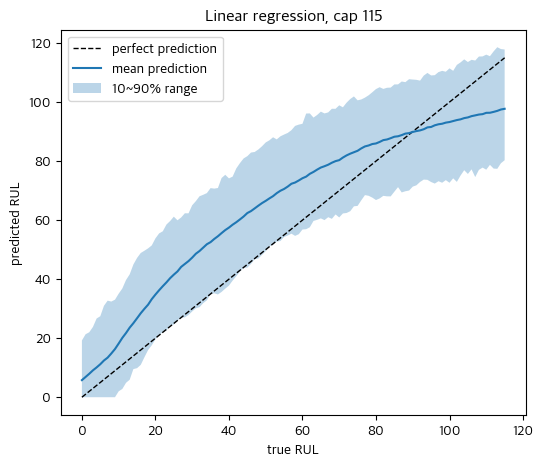

In [11]:
cap = 115
oof = []                                   # 각 행을 '자기가 빠진 폴드의 모델'로 예측한 값
for k in range(5):
    tr, va = feats[feats.fold != k], feats[feats.fold == k]
    m = make_pipeline(StandardScaler(), LinearRegression()).fit(tr[X_cols], cap_rul(tr["RUL"], cap))
    oof.append(va.assign(pred=np.clip(m.predict(va[X_cols]), 0, None)))
oof = pd.concat(oof).query("RUL <= 115")

g = oof.groupby("RUL")["pred"]
plt.figure(figsize=(6, 5))
plt.plot([0, 115], [0, 115], "k--", lw=1, label="perfect prediction")
plt.plot(g.mean().index, g.mean(), label="mean prediction")
plt.fill_between(g.mean().index, g.quantile(.1), g.quantile(.9), alpha=.3, label="10~90% range")
plt.xlabel("true RUL"); plt.ylabel("predicted RUL"); plt.legend(); plt.title("Linear regression, cap 115")
plt.show()

> 해석

실제 RUL이 0일때 예측은 아직 10사이클정도 남았다고 대답. = 늦은 예측
실제 RUL이 120일 때 예측은 90정도라고 대답 = 이른 예측

이유 : 선형회귀는 열화곡선을 따라가지 못함. 또한 모델이 완벽하지 않을 때 모델은 평균쪽으로 끌려가는 영향이 있음(실제로 평균인 82에 끌려가고있음)

### 트리계열 모델을 사용해보자
HistGradientBoostingRegressor을 사용. 여러개의 의사결정 트리를 순서대로 쌓아놓고 이전의 트리가 틀린 부분을 다음 트리가 보정하는 방식.LightGBM와 같은 계열이며 선형회귀가 표현하지 못하는 꺾임과 휘어짐을 표현할 수 있음

rmse       phm_mean        late_ratio      
      mean   std     mean    std       mean   std
cap                                              
115  15.29  1.56     5.42   1.78       0.64  0.08
130  17.73  2.06    10.16   4.22       0.68  0.08
150  20.63  2.55    25.32  13.33       0.69  0.07

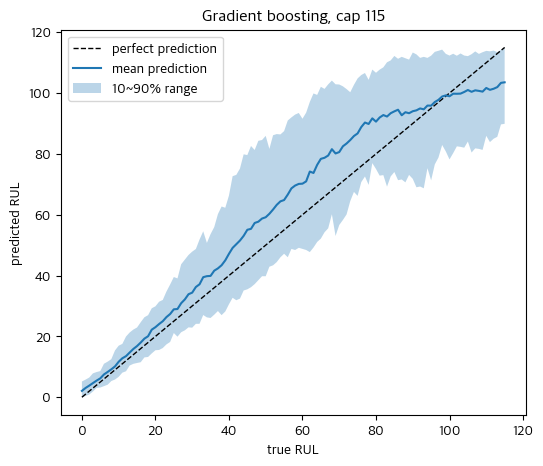

In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor

def cv_run(make_model, cap):
    """5폴드 엔진 단위 교차검증 → (폴드별 점수, 검증 예측값)"""
    rows, oof = [], []
    for k in range(5):
        tr, va = feats[feats.fold != k], feats[feats.fold == k]
        m = make_model().fit(tr[X_cols], cap_rul(tr["RUL"], cap))
        pred = np.clip(m.predict(va[X_cols]), 0, None)
        rows.append({"cap": cap, "fold": k, **evaluate(va["RUL"], pred)})
        oof.append(va.assign(pred=pred))
    return pd.DataFrame(rows), pd.concat(oof)

def plot_pred_vs_true(oof, title):
    o = oof.query("RUL <= 115"); g = o.groupby("RUL")["pred"]
    plt.figure(figsize=(6, 5))
    plt.plot([0, 115], [0, 115], "k--", lw=1, label="perfect prediction")
    plt.plot(g.mean().index, g.mean(), label="mean prediction")
    plt.fill_between(g.mean().index, g.quantile(.1), g.quantile(.9), alpha=.3, label="10~90% range")
    plt.xlabel("true RUL"); plt.ylabel("predicted RUL"); plt.legend(); plt.title(title); plt.show()

make_hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)

res, oofs = [], {}
for cap in [115, 130, 150]:
    r, o = cv_run(make_hgb, cap)
    res.append(r); oofs[cap] = o
hgb = pd.concat(res)
display(hgb.groupby("cap")[["rmse", "phm_mean", "late_ratio"]].agg(["mean", "std"]).round(2))
plot_pred_vs_true(oofs[115], "Gradient boosting, cap 115")

> 해석
- 0-20구간에서는 거의 차이가 없어짐. 1-2정도 차이.실제로 알람을 울려야 하는 구간이 여기임.   
- 그러나 20이상에서는 아직 차이가존재함. 
- 100이상애서는 평평해짐.

선형회귀에서나 트리에서나 상한은 115가 가장 적합함. 115로 잠정 채택

### 윈도우 길이 비교

- 윈도우 길이 10/20/30 비교
- 윈도우가 길면 노이즈를 잘 걸러내지만, 늦게 예측함. 

In [16]:
def cv_run_on(data, make_model, cap, x_cols):
    """cv_run과 같지만, 사용할 특징 데이터를 인자로 받음"""
    rows, oof = [], []
    for k in range(5):
        tr, va = data[data.fold != k], data[data.fold == k]
        m = make_model().fit(tr[x_cols], cap_rul(tr["RUL"], cap))
        pred = np.clip(m.predict(va[x_cols]), 0, None)
        rows.append({"fold": k, **evaluate(va["RUL"], pred)})
        oof.append(va.assign(pred=pred))
    return pd.DataFrame(rows), pd.concat(oof)

def build_feats(N):
    f = make_features(df, N=N).merge(df[["engine_id", "cycle", "RUL"]], on=["engine_id", "cycle"])
    return f.merge(split, on="engine_id").query("role == 'dev'")

summary, oofs_N = [], {}
for N in [30, 40, 50,60]:
    fN = build_feats(N)
    r, o = cv_run_on(fN, make_hgb, cap=115, x_cols=X_cols)
    late = o.query("RUL <= 20")                       # 고장 직전 구간만
    summary.append({
        "N": N,
        "rmse": r.rmse.mean(), "rmse_std": r.rmse.std(),
        "phm_mean": r.phm_mean.mean(), "late_ratio": r.late_ratio.mean(),
        "rmse_RUL<=20": np.sqrt(np.mean((late.pred - late.RUL) ** 2)),
        "bias_RUL<=20": (late.pred - late.RUL).mean(),   # +면 늦게 예측
    })
    oofs_N[N] = o

display(pd.DataFrame(summary).round(2))

,N,rmse,rmse_std,phm_mean,late_ratio,rmse_RUL<=20,bias_RUL<=20
0,30,13.29,0.96,3.27,0.62,3.75,1.38
1,40,12.94,0.66,3.07,0.61,3.96,1.23
2,50,12.68,0.79,2.99,0.60,3.91,1.03
3,60,12.87,0.89,3.18,0.61,4.10,1.19



|N|rmse|rmse_std|phm_mean|late_ratio|rmse_RUL<=20|bias_RUL<=20|
|----|----|----|----|----|----|----|
|10|18.71|2.11|12.01|0.63|6.27|2.92|
|20|15.29|1.56|5.42|0.64|4.50|1.82|
|30|13.29|0.96|3.27|0.62|3.75|1.38|


- rmse: 전체 오차. 보통 N이 길수록 조금 좋아짐.
- rmse_RUL<=20, bias_RUL<=20: 고장 직전(20사이클 이내) 오차와 치우침. N이 길수록 bias가 +쪽으로 커지면 "윈도우가 길어서 늦게 알아챈다"는 신호
- 선택 기준: 전체 오차 차이가 작다면(std 1.5 정도 안쪽이면 사실상 같은 수준), 고장 직전 구간이 더 좋은 쪽을 고른다.

n을 늘려서 30~60까지 다시 계산했을 때 40이상부터는 고장 근접 구간에서 오히려 rmse가 커짐. 따라서 window=30이 적합